# Kalman Filter

Variables:
- x – system state estimated (x, y, vx, vy)
- z – actual sensor measurement
- u – control input

Matrices:
- P - state estimate error covariance matrix
- R - measurement error covariance matrix
- Q – process noise covariance matrix (the noise because of unknown properties of the modeled system like different forces affect the object)
- F - state transition matrix
- H - state-to-measure space mapping matrix
- K - Kalman gain: how much we trust the measurement vs. prediction (how much should I shift prediction toward the measurement?)

## Prediction step

1. $x' = F \cdot x + u$ – predict the next state from the current state and control input
2. $P'= F \cdot P \cdot F^T + Q$ - propagate uncertainty through model

## Measurement update step

1. $y = z - H \cdot x$ – difference between actual and expected measurement
2. $S = H \cdot P \cdot H^T + R$ – uncertainty in prediction + measurement
3. $K = P \cdot H^T \cdot S^{-1}$ - trust the measurement vs. prediction
4. $x' = x + K \cdot y$ - update state estimate
5. $P' = (I - K \cdot H) \cdot P$ - update uncertainty estimate (reduced by measurement usage).

In [17]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

In [18]:
def show(img: np.ndarray, dpi=100, title=None, to_rgb=True) -> None:
    if to_rgb:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.figure(dpi=dpi)
    plt.imshow(img)
    if title is not None:
        plt.title(title)
    plt.show()

In [9]:
def get_filter(state_post):
    kalman_2d = cv2.KalmanFilter(
        dynamParams=4,  # Dimensionality of the state.
        measureParams=2,  # Dimensionality of the measurement.
        controlParams=0,  # Dimensionality of the control vector.
    )

    # F - state transition matrix.
    # x' = x + v * dt
    kalman_2d.transitionMatrix = np.array([[1, 0, 1, 0],
                                           [0, 1, 0, 1],
                                           [0, 0, 1, 0],
                                           [0, 0, 0, 1]], np.float32)

    # H - map state vector to measurement vector
    kalman_2d.measurementMatrix = np.array([[1, 0, 0, 0],
                                            [0, 1, 0, 0]], np.float32)

    # P - state covariance matrix
    # The larger values (errors) - the quicker update
    kalman_2d.errorCovPost = np.eye(4, dtype=np.float32)

    # R - measurement covariance matrix
    # The larger values (errors) - the slower update
    kalman_2d.measurementNoiseCov = np.eye(2,
                                           dtype=np.float32)

    # Q - the noise because of unknown parameters of the system
    # The larger values (errors) - the quicker update
    kalman_2d.processNoiseCov = np.array([[0.3, 0, 0, 0],
                                          [0, 0.3, 0, 0],
                                          [0, 0, 0.8, 0],
                                          [0, 0, 0, 0.8]], np.float32)

    kalman_2d.statePre = state_post
    kalman_2d.statePost = state_post

    return kalman_2d

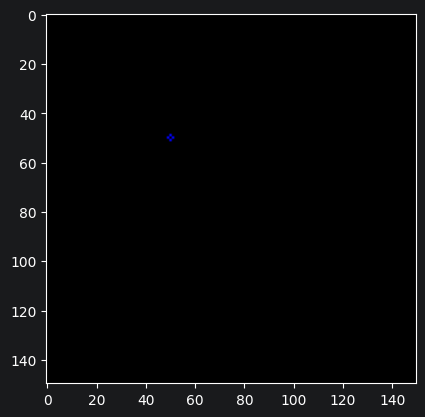

In [10]:
# Static point with noise measured
data = np.array([
    [50, 50],
    [51, 51],
    [50, 50],
    [51, 51],
    [50, 50],
])

field = np.zeros((150, 150, 3), dtype=np.uint8)
kalman_2d = get_filter(np.array([[data[0][0]], [data[0][1]], [0], [0]], np.float32))

for idx in range(1, 50):
    kalman_2d.correct(data[idx % len(data)].reshape((2, 1)).astype(np.float32))

for i in range(100):
    p = kalman_2d.predict()
    cv2.circle(field, p.reshape(-1)[:2].astype(int), 1, (255, 0, 0), 1)

show(field)

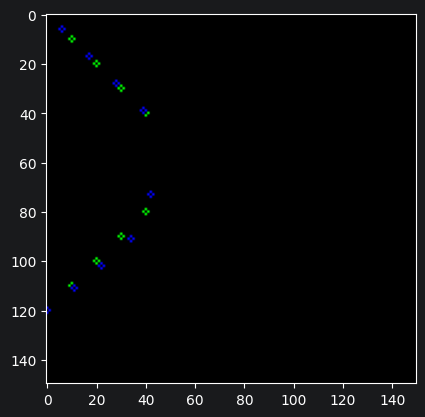

In [13]:
# Missing values is measurements
data = np.array([
    [0, 0],
    [10, 10],
    [20, 20],
    [30, 30],
    [40, 40],

    # [50, 50],
    # [60, 60],
    # [50, 70],

    [40, 80],
    [30, 90],
    [20, 100],
    [10, 110],
    [0, 120],
])

field = np.zeros((150, 150, 3), dtype=np.uint8)
kalman_2d = get_filter(np.array([[data[0][0]], [data[0][1]], [0], [0]], np.float32))

for idx in range(1, len(data)):
    p = kalman_2d.predict()
    kalman_2d.correct(data[idx].reshape((2, 1)).astype(np.float32))
    cv2.circle(field, data[idx], 1, (0, 255, 0), 1)
    cv2.circle(field, p.reshape(-1)[:2].astype(int), 1, (255, 0, 0), 1)

show(field)

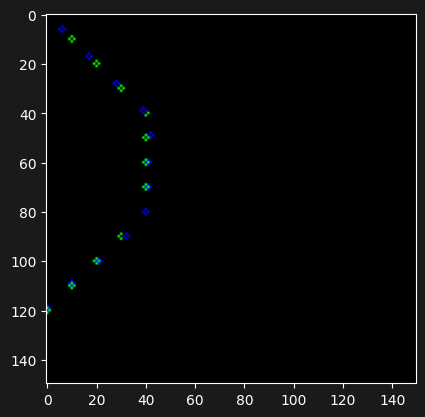

In [14]:
# Without missing values + interpolation
data = np.array([
    [0, 0],
    [10, 10],
    [20, 20],
    [30, 30],
    [40, 40],

    [40, 50],
    [40, 60],
    [40, 70],

    [40, 80],
    [30, 90],
    [20, 100],
    [10, 110],
    [0, 120],
])

field = np.zeros((150, 150, 3), dtype=np.uint8)
kalman_2d = get_filter(np.array([[data[0][0]], [data[0][1]], [0], [0]], np.float32))

last_state = None
for idx in range(1, len(data)):
    data_item = data[idx].reshape((2, 1))
    p = kalman_2d.predict()
    kalman_2d.correct(data_item.astype(np.float32))

    cv2.circle(field, data[idx], 1, (0, 255, 0), 1)
    cv2.circle(field, p.reshape(-1)[:2].astype(int), 1, (255, 0, 0), 1)

show(field)

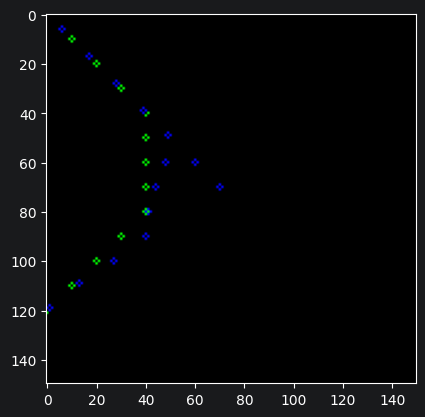

In [15]:
# With missing values + interpolation + return to the prev state
data = np.array([
    [0, 0],
    [10, 10],
    [20, 20],
    [30, 30],
    [40, 40],

    [40, 50],
    [40, 60],
    [40, 70],

    [40, 80],
    [30, 90],
    [20, 100],
    [10, 110],
    [0, 120],
])

field = np.zeros((150, 150, 3), dtype=np.uint8)
kalman_2d = get_filter(np.array([[data[0][0]], [data[0][1]], [0], [0]], np.float32))

last_state = None
for idx in range(1, len(data)):
    data_item = data[idx].reshape((2, 1))
    if data_item[1] == 80:
        kalman_2d.statePost = last_state[0]
        kalman_2d.errorCovPost = last_state[1]
        p = kalman_2d.predict()
        cv2.circle(field, p.reshape(-1)[:2].astype(int), 1, (255, 0, 0), 1)
        kalman_2d.correct(np.array([[40], [50]]).astype(np.float32))
        p = kalman_2d.predict()
        cv2.circle(field, p.reshape(-1)[:2].astype(int), 1, (255, 0, 0), 1)
        kalman_2d.correct(np.array([[40], [60]]).astype(np.float32))
        p = kalman_2d.predict()
        cv2.circle(field, p.reshape(-1)[:2].astype(int), 1, (255, 0, 0), 1)
        kalman_2d.correct(np.array([[40], [70]]).astype(np.float32))

    p = kalman_2d.predict()
    if data_item[1] not in [50, 60, 70]:
        kalman_2d.correct(data_item.astype(np.float32))
    if data_item[1] == 40:
        last_state = kalman_2d.statePost.copy(), kalman_2d.errorCovPost.copy()

    cv2.circle(field, data[idx], 1, (0, 255, 0), 1)
    cv2.circle(field, p.reshape(-1)[:2].astype(int), 1, (255, 0, 0), 1)

show(field)

# Sinusoid modeling

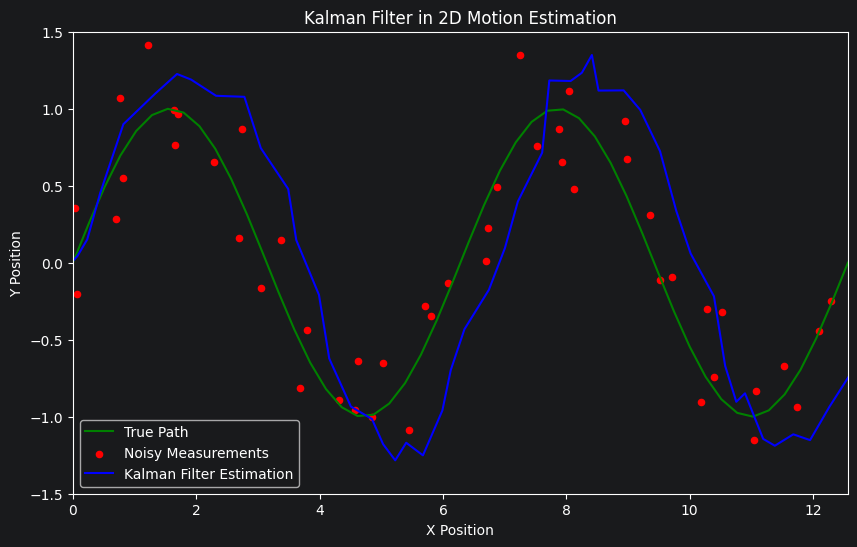

In [16]:
num_steps = 50
noise_std = 0.2
x_vals = np.linspace(0, 4 * np.pi, num_steps)
true_path = np.array([x_vals, np.sin(x_vals)]).T  # Sinusoidal path

# Placeholder for results
predictions = []
measurements = []

kalman_2d = cv2.KalmanFilter(4, 2)

# state transition matrix - A
kalman_2d.transitionMatrix = np.array([[1, 0, 1, 0],
                                       [0, 1, 0, 1],
                                       [0, 0, 1, 0],
                                       [0, 0, 0, 1]], np.float32)

# map state vector to measurements vector - H
kalman_2d.measurementMatrix = np.array([[1, 0, 0, 0],
                                        [0, 1, 0, 0]], np.float32)
# the noise because of measurement inaccuracies - R
kalman_2d.measurementNoiseCov = np.eye(2, dtype=np.float32) * 1.0

# the noise because of unknown properties of modeled system (forces affected the ball) - Q
kalman_2d.processNoiseCov = np.array([[1, 0, 0, 0],
                                      [0, 1, 0, 0],
                                      [0, 0, 1, 0],
                                      [0, 0, 0, 1]], np.float32) * 0.01

# kalman_2d.errorCovPost = np.eye(4, dtype=np.float32) * 100
kalman_2d.statePost = np.array([[0], [0], [0], [0]], np.float32)

for point in true_path:
    # Simulate noisy measurement
    measurement = point + np.random.normal(0, noise_std, 2)
    measurements.append(measurement)

    # Kalman predict and correct steps
    prediction = kalman_2d.predict()
    predictions.append(prediction)
    kalman_2d.correct(np.array([[measurement[0]], [measurement[1]]], np.float32))

fig, ax = plt.subplots(figsize=(10, 6))
ax.set_xlim(0, 4 * np.pi)
ax.set_ylim(-1.5, 1.5)
ax.set_title("Kalman Filter in 2D Motion Estimation")
ax.set_xlabel("X Position")
ax.set_ylabel("Y Position")

# Plotting the true path, noisy measurements, and Kalman filter estimations
ax.plot(true_path[:, 0], true_path[:, 1], 'g-', label="True Path")
ax.scatter(np.array(measurements)[:, 0], np.array(measurements)[:, 1], c='red', s=20, label="Noisy Measurements")
ax.plot(np.array(predictions)[:, 0, 0], np.array(predictions)[:, 1, 0], 'b-', label="Kalman Filter Estimation")
ax.legend()
plt.show()